# Random Forest Regression: optimized model and evaluation

This notebook shows the **actual completed run**. Run All loads saved models and verifies their predictions; it does not start a new search unless you set `RUN_TRAINING = True`. Study the numbered explanations in order. The original baseline notebook and outputs remain in this folder.

## 1. Import the tools
`pandas` reads tables, `joblib` loads fitted models, and the shared module contains the optimization code. `X` means input features and `y` means actual energy usage.

In [1]:
from pathlib import Path
import sys
import json
import joblib
import pandas as pd
import numpy as np
from IPython.display import display, Image

start = Path.cwd()
ROOT = next(p for p in [start, *start.parents] if (p / "src" / "optimized_regression.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.optimized_regression import run, make_estimator
from src.regression_common import load_data, split_for_validation, score_predictions

## 2. Set paths and the optional training switch
Training is already complete. Keeping this switch False lets you inspect the results quickly during the viva. Setting it True repeats the full optimization and replaces only `outputs_optimized`.

In [2]:
KIND = 'forest'
OUTPUT_DIR = ROOT / 'random forest' / "outputs_optimized"
ARTIFACTS_DIR = ROOT.parent / "FDM" / "artifacts"
RUN_TRAINING = False
if RUN_TRAINING:
    run(KIND, ARTIFACTS_DIR, OUTPUT_DIR, jobs=4)

## 3. Load the common data and check the dates
January-August fits candidates. September-October chooses settings. The chosen configuration is then fitted again on January-October before evaluating November onward. Dates stay ordered because this is forecasting.

In [3]:
X_train, X_test, y_train, y_test = load_data(ARTIFACTS_DIR)
X_fit, X_val, y_fit, y_val = split_for_validation(X_train, y_train)
display(pd.DataFrame([{"purpose": name, "rows": len(X), "first": X.index.min(), "last": X.index.max()} for name, X in [("Fit", X_fit), ("Validation", X_val), ("Refit", X_train), ("Test", X_test)]]))

,purpose,rows,first,last
0,Fit,22655,2018-01-08 00:15:00,2018-08-31 23:45:00
1,Validation,5856,2018-09-01 00:00:00,2018-10-31 23:45:00
2,Refit,28511,2018-01-08 00:15:00,2018-10-31 23:45:00
3,Test,5857,2018-11-01 00:00:00,2019-01-01 00:00:00


## 4. Inspect the chosen settings
The configuration was fixed using validation RMSE before this run's test score was calculated. Reading old test scores does not make this an entirely untouched test set. The metadata records the exact settings and assumptions.

In [4]:
metadata = json.loads((OUTPUT_DIR / "run_metadata.json").read_text())
settings = metadata["settings"]
print(json.dumps(settings["selected_specification"], indent=2))
print("Input columns:", settings["raw_input_features"])
print("Columns after feature engineering:", settings["transformed_features"])

{
  "feature_mode": "context",
  "max_depth": 12,
  "max_features": 0.4,
  "max_samples": null,
  "min_samples_leaf": 1,
  "min_samples_split": 10,
  "n_estimators": 800
}
Input columns: 15
Columns after feature engineering: 24


## 5. Build an untrained copy
This cell creates the selected architecture without learning. `.fit(X, y)` is what learns from examples. The final layer remains `LinearRegression` for the linear experiment or `RandomForestRegressor` for the forest. Negative energy predictions are floored at zero by the saved wrapper.

In [5]:
untrained_model = make_estimator(KIND, settings["selected_specification"])
print(untrained_model)

EnergyRegressor(estimator=Pipeline(steps=[('features',
                                           ForecastFeatures(mode='context')),
                                          ('regressor',
                                           RandomForestRegressor(max_depth=12,
                                                                 max_features=0.4,
                                                                 min_samples_split=10,
                                                                 n_estimators=800,
                                                                 n_jobs=4,
                                                                 random_state=42))]))


## 6. Understand the optimization
For Linear Regression, we compared raw inputs, interaction/quadratic features, time-of-day effects and spline basis functions. A spline is a set of smooth curve features; ordinary least squares still learns their coefficients. For Random Forest, we used a seeded random search and then tested 400/800 trees for four promising configurations. More trees are only kept when validation supports them. These searches are finite, not proof of a global optimum.

In [6]:
trials = pd.read_csv(OUTPUT_DIR / "validation_trials.csv")
print("Candidates evaluated:", len(trials))
display(trials[["trial", "stage", "RMSE_kWh", "MAE_kWh", "R2", "specification"]].head(10))

Candidates evaluated: 46


,trial,stage,RMSE_kWh,MAE_kWh,R2,specification
0,40,more_trees,9.128742,4.254324,0.914467,"{""feature_mode"": ""context"", ""max_depth"": 12, ""..."
1,39,more_trees,9.134522,4.254417,0.914359,"{""feature_mode"": ""context"", ""max_depth"": 12, ""..."
2,28,initial,9.144823,4.260963,0.914166,"{""feature_mode"": ""context"", ""max_depth"": 12, ""..."
3,44,more_trees,9.154581,4.237549,0.913982,"{""feature_mode"": ""context"", ""max_depth"": 16, ""..."
4,43,more_trees,9.161063,4.243446,0.913861,"{""feature_mode"": ""context"", ""max_depth"": 16, ""..."
5,41,more_trees,9.166701,4.224750,0.913755,"{""feature_mode"": ""context"", ""max_depth"": 16, ""..."
6,42,more_trees,9.178521,4.226561,0.913532,"{""feature_mode"": ""context"", ""max_depth"": 16, ""..."
7,2,initial,9.180064,4.228351,0.913503,"{""feature_mode"": ""context"", ""max_depth"": 16, ""..."
8,33,initial,9.197608,4.255513,0.913172,"{""feature_mode"": ""context"", ""max_depth"": 16, ""..."
9,45,more_trees,9.202250,4.247463,0.913084,"{""feature_mode"": ""context"", ""max_depth"": 12, ""..."


## 7. Compare original and optimized results
MAE is average absolute error; RMSE gives larger errors more weight. Both are measured in kWh and lower is better. R2 is a score, not an accuracy percentage. Use validation to select settings, and test results to report what happened after fitting.

In [7]:
baseline = pd.read_csv(OUTPUT_DIR.parent / "outputs" / "metrics.csv")
optimized = pd.read_csv(OUTPUT_DIR / "metrics.csv")
comparison = pd.concat([baseline.assign(version="Original"), optimized.assign(version="Optimized")], ignore_index=True)
display(comparison[["version", "model", "split", "MAE_kWh", "RMSE_kWh", "R2"]])

,version,model,split,MAE_kWh,RMSE_kWh,R2
0,Original,Random Forest Regression,validation,4.276795,9.266678,0.911863
1,Original,Persistence,validation,5.826918,12.960453,0.827595
2,Original,Random Forest Regression,train,3.107908,6.542302,0.962267
3,Original,Random Forest Regression,test,3.847429,8.204323,0.930553
4,Original,Persistence,test,5.155235,11.812549,0.856036
5,Optimized,Random Forest Regression,validation,4.254324,9.128742,0.914467
6,Optimized,Persistence,validation,5.826918,12.960453,0.827595
7,Optimized,Random Forest Regression,train,3.619595,7.385566,0.951913
8,Optimized,Random Forest Regression,test,3.839260,8.082553,0.932599
9,Optimized,Persistence,test,5.155235,11.812549,0.856036


## 8. Load the final trained model and verify it
This file includes fitted preprocessing and prediction rules. It receives the same 15 unscaled inputs as the original model. We compare fresh predictions with the saved CSV to check reproducibility.

In [8]:
model = joblib.load(OUTPUT_DIR / "model.joblib")
predictions = model.predict(X_test)
saved_predictions = pd.read_csv(OUTPUT_DIR / "test_predictions.csv", index_col=0)
np.testing.assert_allclose(predictions, saved_predictions["predicted_kWh"], rtol=1e-10, atol=1e-8)
display(pd.DataFrame([score_predictions("Reloaded optimized model", "test", y_test, predictions)]))
print("Reload verification passed.")

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2
0,Reloaded optimized model,test,5857,3.83926,8.082553,0.932599


Reload verification passed.


## 9. Inspect predictions and errors
The first plot shows actual and predicted usage over seven test days. The diagonal in the second plot is perfect prediction. The last plot shows how far predictions miss the actual readings.

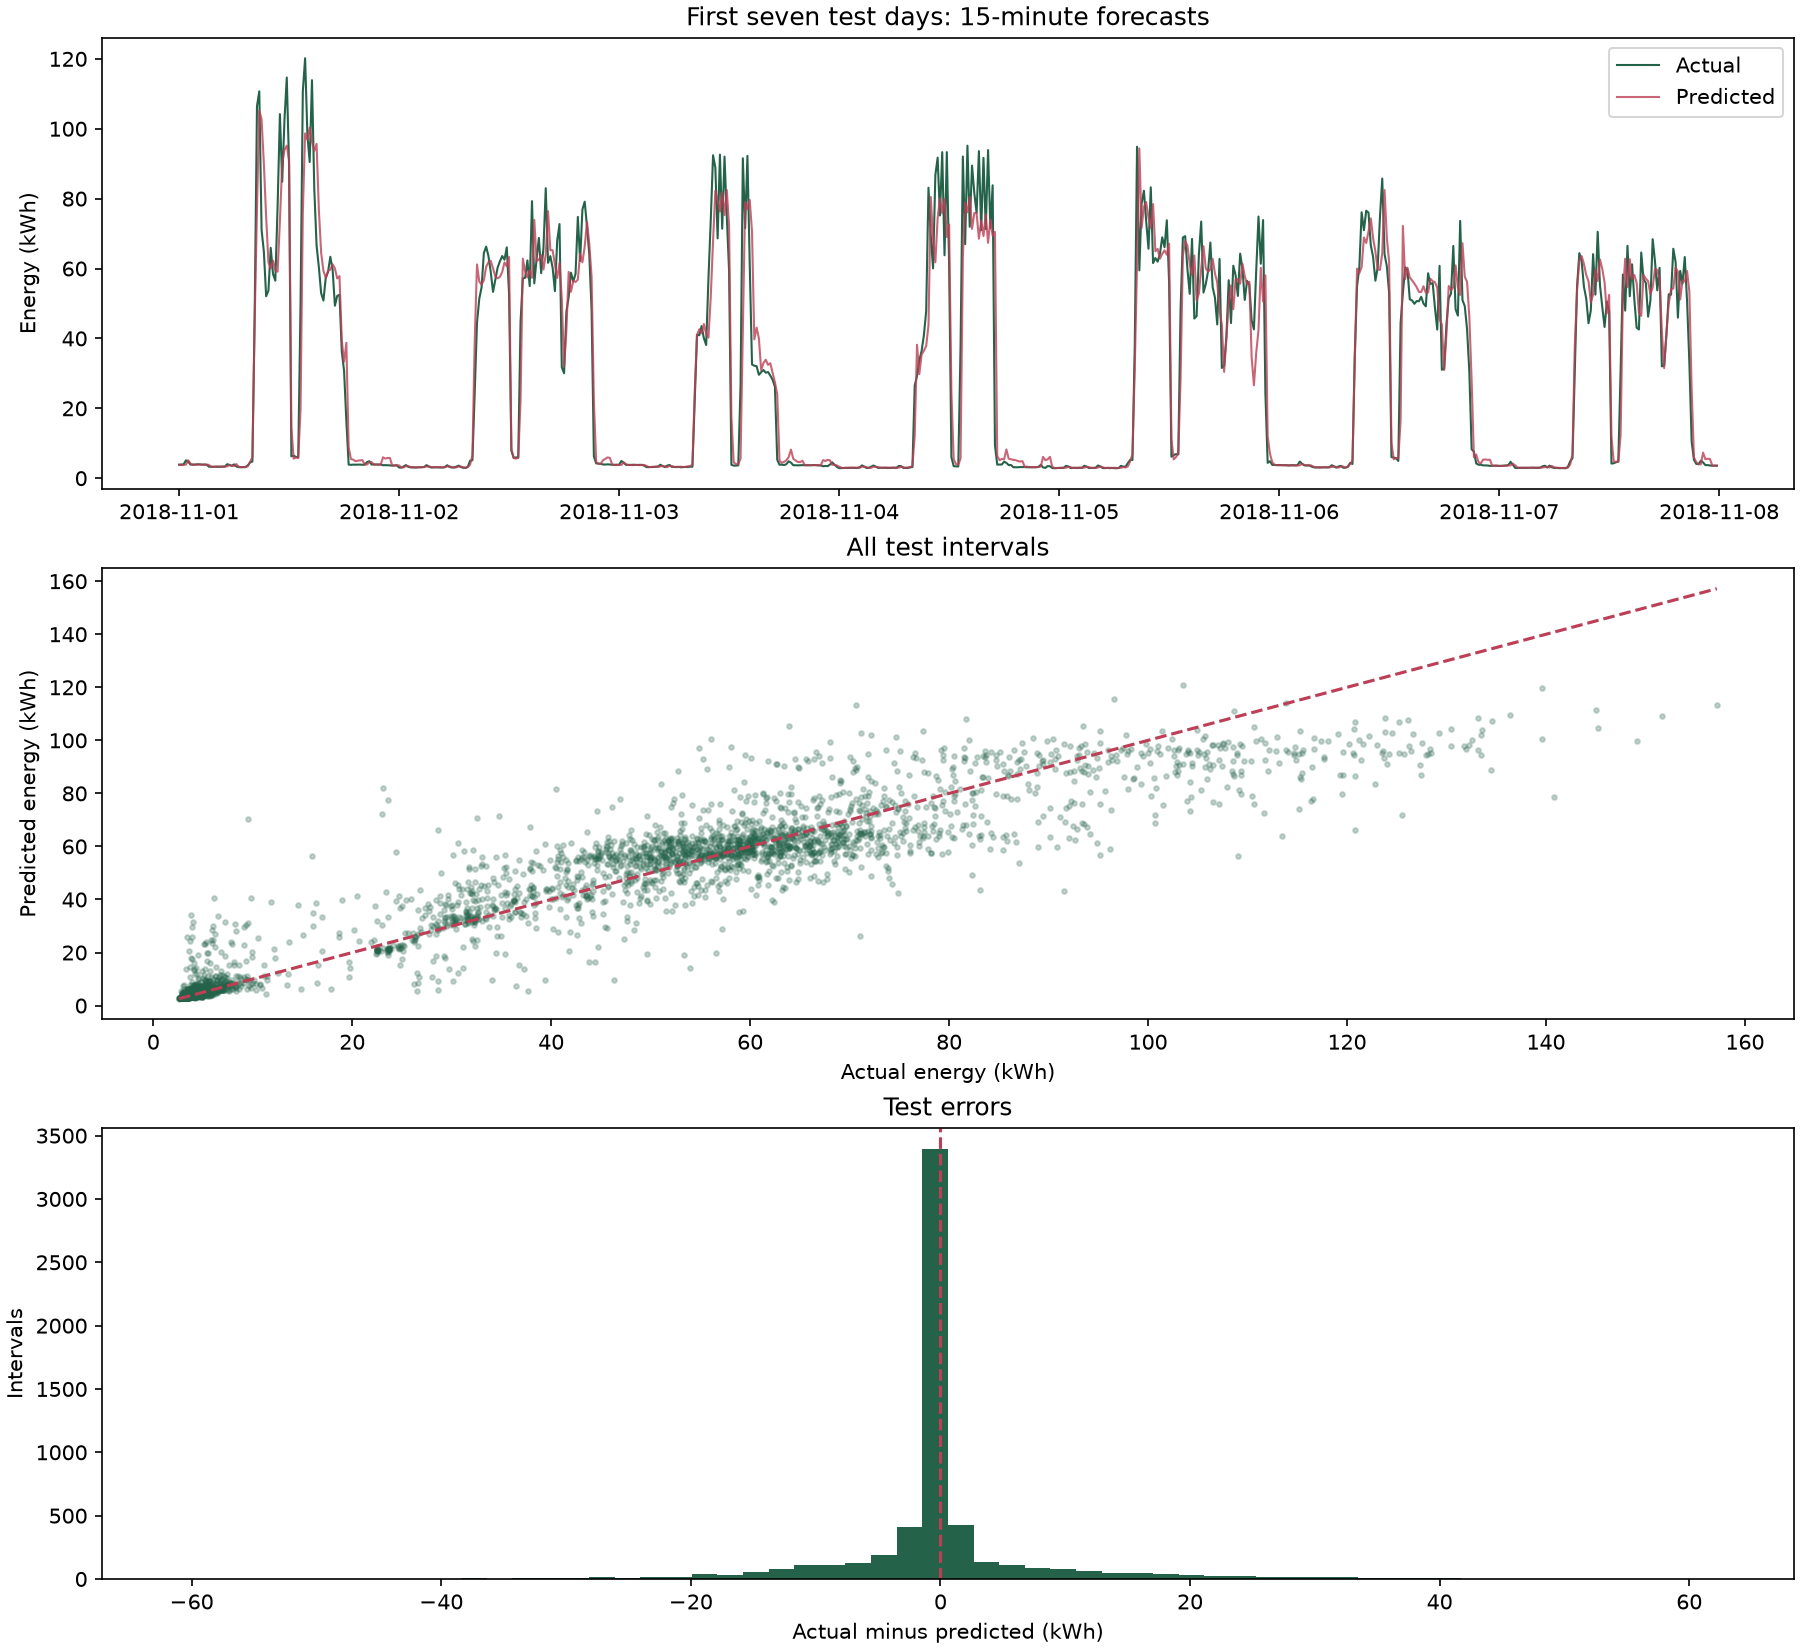

,actual_kWh,predicted_kWh,persistence_kWh,residual_kWh
timestamp,,,,
2018-11-01 00:00:00,3.85,3.843782,3.92,0.006218
2018-11-01 00:15:00,3.89,3.809878,3.85,0.080122
2018-11-01 00:30:00,3.96,3.818255,3.89,0.141745
2018-11-01 00:45:00,5.11,3.880148,3.96,1.229852
2018-11-01 01:00:00,4.72,5.102319,5.11,-0.382319


In [9]:
display(Image(filename=str(OUTPUT_DIR / "evaluation.png")))
display(saved_predictions.head())

## 10. Inspect the learned relationships
For the forest, impurity importance describes how inputs helped tree splits. For Linear Regression, coefficients describe weights on engineered features. Neither proves cause and effect. Correlated features make individual values harder to interpret.

In [10]:
effects = pd.read_csv(OUTPUT_DIR / "feature_effects.csv")
if "coefficient_standardized_basis" in effects:
    effects = effects.assign(magnitude=effects["coefficient_standardized_basis"].abs()).sort_values("magnitude", ascending=False)
display(effects.head(15))

,feature,impurity_importance
0,lag_1,0.364924
1,daily_deviation,0.184799
2,relative_daily_usage,0.139020
3,lag_2_reconstructed,0.078510
4,roll_mean_4,0.048644
5,roll_std_4,0.028841
6,relative_recent_usage,0.022308
7,lag_3_reconstructed,0.018236
8,lag_672,0.017680
9,tod_cos,0.012922


## 11. Check robustness and the load-category assumption
Walk-forward diagnostics fit earlier months and predict later months. These are retrospective checks of settings selected using September-October, so they are not an independent cross-validation estimate. The load ablation checks what happens when `load_level` is removed; it does not establish whether the real system knows the load category in advance.

In [11]:
display(pd.read_csv(OUTPUT_DIR / "walk_forward_diagnostics.csv"))
display(pd.read_csv(OUTPUT_DIR / "load_level_ablation.csv"))
for limitation in metadata["limitations"]:
    print("-", limitation)

,model,split,n_rows,MAE_kWh,RMSE_kWh,R2,fit_rows,validation_end_exclusive
0,Selected configuration,2018-05,5856,4.877405,10.046040,0.900291,10847,2018-07-01
1,Persistence,2018-05,5856,5.952602,13.542858,0.818797,10847,2018-07-01
2,Selected configuration,2018-07,5952,4.286387,8.989783,0.917840,16703,2018-09-01
3,Persistence,2018-07,5952,5.834533,13.044218,0.827019,16703,2018-09-01
4,Random Forest Regression,validation,5856,4.254324,9.128742,0.914467,22655,2018-11-01
5,Persistence,validation,5856,5.826918,12.960453,0.827595,22655,2018-11-01


,model,split,n_rows,MAE_kWh,RMSE_kWh,R2
0,"Selected, includes load_level",validation,5856,4.254324,9.128742,0.914467
1,"Selected, without load_level",validation,5856,4.317268,9.199282,0.913140


- Forecasts are one interval ahead (15 minutes), with previous actual readings available before each prediction. This is not a day-ahead test.
- load_level assumes the operating load category is known before the forecast interval; this must be confirmed with the team.
- The supplied preprocessing shifts midnight rows to the next day; the original interval timestamp convention remains an assumption.
- The supplied preprocessing interpolates the target at 2018-11-08 00:00 using a future reading. This affects that test target and later lag/rolling features. Test results describe those supplied artifacts, not a fully causal evaluation of raw measurements.
- Upstream feature selection used the entire supplied training period, including September/October. Validation is provisional conditional on that fixed feature set; strict validation needs feature selection refitted on the earlier fitting period.
- The preprocessing notebook already inspected the test persistence score and full-dataset ED

## 12. Explain your contribution
A useful explanation is: 'I developed a baseline, optimized it using chronological validation, refitted the selected configuration on all training rows, compared MAE/RMSE/R2 against the baseline and persistence, and saved a reproducible model.' Add your actual selected settings and scores. Read `../reports/MODEL_OPTIMIZATION_REPORT.md` for the group handover and remaining tasks.

The full training implementation is in `../src/optimized_regression.py`. To repeat it from the terminal, run the command below; this Markdown cell does not execute it.

```bash
python "random forest/optimize.py" --train
```